# 01 · Exploración de datos — Sprint 1 (F2)
> **Datos 100 % sintéticos.** AURORA SCORE y Vertex Financial Group son un caso ficticio con fines académicos (SCY1102, Duoc UC). Ejecutar antes `python src/pipeline.py`.

Objetivo: verificar que las seis fuentes sintéticas reproducen la estructura y los sesgos documentados en el informe de factibilidad (EP1) antes de modelar. Tarjetas AUR-02, AUR-03, AUR-04, AUR-05.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
REP = RAIZ / "reports"; FIG = REP / "figures"
leer = lambda n: json.loads((REP / n).read_text(encoding="utf-8"))

## 1. Volumen por fuente

In [2]:
g = leer('resumen_generador.json')
pd.Series(g['filas_por_fuente'], name='filas').to_frame()

,filas
solicitudes,42000
telecom_lineas,42000
telecom_actividad,234824
servicios,484419
marketplace,154193
app_metadatos,42000
redes_optin,21987
biometria,42000


## 2. Auditoría de representatividad (RP-04)
La cohorte histórica, que es la base de entrenamiento, se compara con la cohorte reciente, que representa a la población objetivo.

In [3]:
comp = {(a, coh): v for a, d in g['composicion'].items() for coh, v in d.items()}
pd.DataFrame(comp).T.round(3).fillna('')

C:\Users\Panchuuu\AppData\Local\Temp\ipykernel_27872\3262553264.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(comp).T.round(3).fillna('')


urbana  rural      M      F  25-45  46-59  18-24    60+ formal informal     CL     PE     CO     MX
zona           historica  0.903  0.097                                                                                      
               reciente   0.818  0.182                                                                                      
genero         historica                 0.59   0.41                                                                        
               reciente                 0.502  0.498                                                                        
tramo_edad     historica                              0.619  0.228  0.113   0.04                                            
               reciente                               0.518  0.262  0.139  0.081                                            
sector_laboral historica                                                           0.59     0.41                            
               reciente                                                           0.524    0.476                            
pais           historica                                                                          0.364   0.29  0.199  0.147
               reciente                                                                           0.346  0.299  0.208  0.146

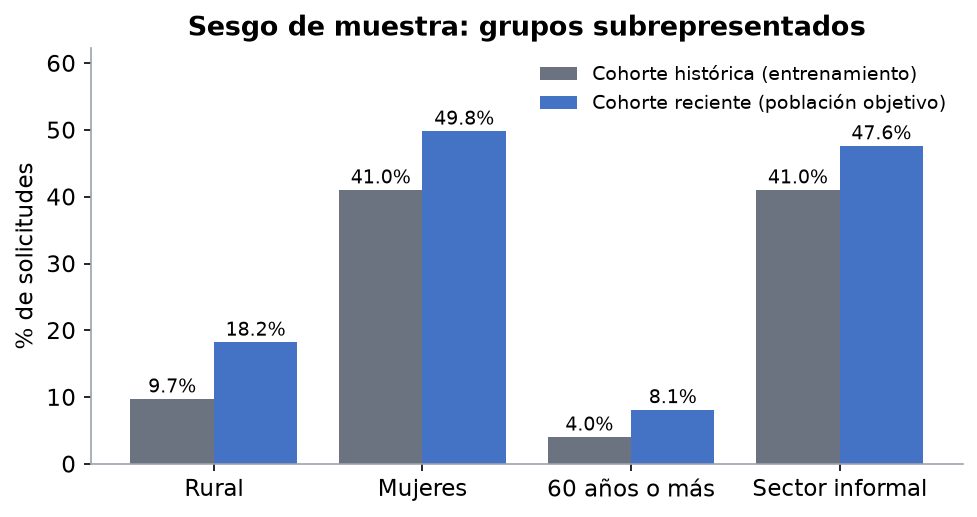

In [4]:
display(Image(FIG / '01_sesgo_muestra.png', width=700))

## 3. Mora real vs. mora registrada (sesgo de medición)
La mora real, que en el dato sintético se conoce, es pareja entre grupos. La registrada no lo es: los pagos en corresponsal se concilian con rezago.

In [5]:
pd.DataFrame({'real': {f'{a}={k}': v for a, d in g['incumplio_real_por_grupo'].items() for k, v in d.items()},
              'registrada': {f'{a}={k}': v for a, d in g['incumplio_registrado_por_grupo'].items() for k, v in d.items()}}).round(4)

,real,registrada
zona=rural,0.1119,0.2154
zona=urbana,0.1088,0.1565
genero=F,0.1113,0.1700
genero=M,0.1075,0.1588
tramo_edad=18-24,0.1109,0.1648
tramo_edad=25-45,0.1081,0.1624
tramo_edad=46-59,0.1107,0.1622
tramo_edad=60+,0.1097,0.1822
sector_laboral=formal,0.1100,0.1525
sector_laboral=informal,0.1080,0.1785


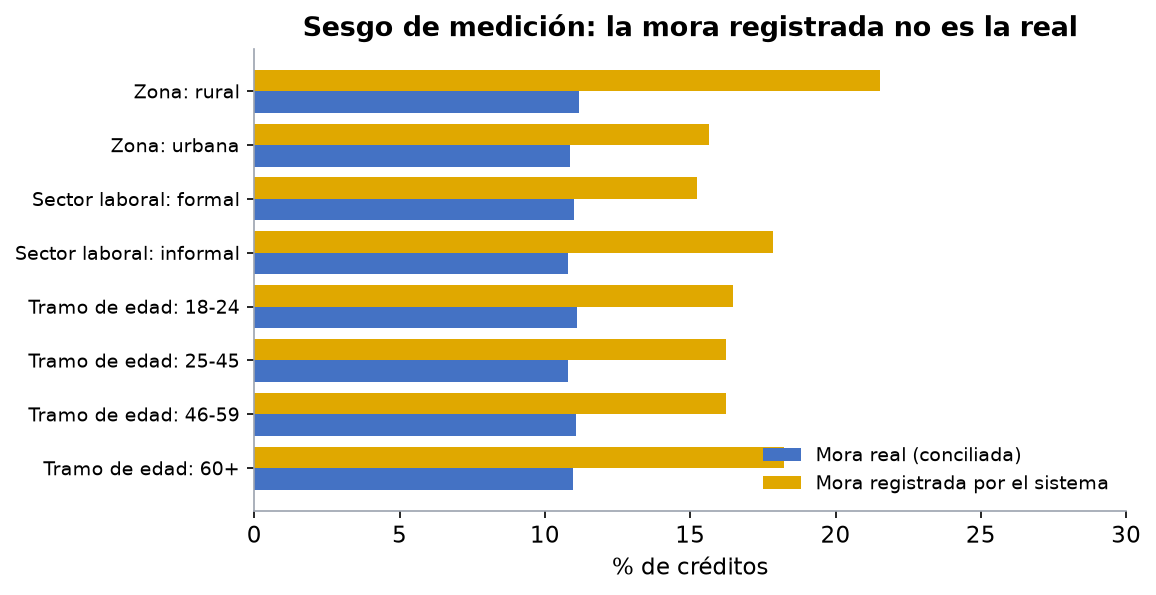

In [6]:
display(Image(FIG / '02_sesgo_medicion.png', width=700))

## 4. Calidad de la ingesta: identidad y rezago (RF-01, RF-02)

In [7]:
q = leer('calidad_ingesta.json')
display(pd.DataFrame(q['identidad']))
display(pd.DataFrame(q['rezago']))

,fuente,llave,filas,enlazadas,tasa_enlace,invalidas
0,telecom_lineas,numero_movil,42000,42000,1.0000,0
1,telecom_actividad,numero_movil,234824,234824,1.0000,0
2,servicios,rut_dni_titular,484419,477347,0.9854,1844
3,marketplace,email_sha256,154193,154193,1.0000,0
4,app_metadatos,solicitud_id,42000,42000,1.0000,0
5,redes_optin,solicitud_id,21987,21987,1.0000,0
6,biometria,solicitud_id,42000,42000,1.0000,0


,fuente,filas_enlazadas,no_disponibles_por_rezago,pct_no_disponible,rezago_medio_h
0,telecom_actividad,234824,2123,0.90,36.0
1,servicios,477347,5937,1.24,48.0
2,marketplace,154193,1791,1.16,48.0


## 5. Una muestra de cada fuente cruda

In [8]:
for f in ['telecom_lineas', 'servicios', 'marketplace']:
    print(f); display(pd.read_parquet(RAIZ / 'data/raw' / f'{f}.parquet').head(3))

telecom_lineas


,numero_movil,operador,tipo_plan,marca_telefono,gama_equipo,antiguedad_linea_meses,comuna_antena
0,+56 9 5190 3169,Entel,prepago,ZTE Blade,baja,39,CL-C27
1,526544285190,Telcel,postpago,Pixel,alta,22,MX-C23
2,56979304684,Movistar,postpago,Galaxy A,media,65,CL-C19


servicios


,rut_dni_titular,tipo_servicio,mes_rel,monto,dias_atraso_registrado,fecha_pago_efectiva_dias_atraso,canal_pago,dias_antes_solicitud,rezago_horas
0,17714737-0,electricidad,-1,78.61,0.0,0.0,digital,25,44
1,177147370,electricidad,-2,31.52,2.0,2.0,digital,32,58
2,17.714.737-0,electricidad,-3,46.81,0.0,0.0,digital,73,50


marketplace


,email_sha256,mes_rel,n_compras,ticket_promedio,n_reclamos,n_devoluciones,dias_antes_solicitud,rezago_horas
0,b8f8000bb586761c5399eb48ff4ab46747a69699e648c0...,-1,0,20.90,0,0,21,40
1,b8f8000bb586761c5399eb48ff4ab46747a69699e648c0...,-2,5,39.51,0,0,51,54
2,b8f8000bb586761c5399eb48ff4ab46747a69699e648c0...,-3,2,38.99,0,0,69,64
